In [1]:
import pandas as pd

fake = pd.read_csv("../data/raw/Fake.csv")
true = pd.read_csv("../data/raw/True.csv")

print("Fake news shape:", fake.shape)
print("Real news shape:", true.shape)


Fake news shape: (23481, 4)
Real news shape: (21417, 4)


In [2]:
print("Fake News Columns:")
print(fake.columns.tolist())

print("\nReal News Columns:")
print(true.columns.tolist())

Fake News Columns:
['title', 'text', 'subject', 'date']

Real News Columns:
['title', 'text', 'subject', 'date']


In [3]:
display(fake.head())

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
display(fake.head())

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [5]:
print("FAKE NEWS")
print(fake.isnull().sum())

print("\nREAL NEWS")
print(true.isnull().sum())

FAKE NEWS
title      0
text       0
subject    0
date       0
dtype: int64

REAL NEWS
title      0
text       0
subject    0
date       0
dtype: int64


In [6]:
print("Duplicate fake articles:", fake.duplicated().sum())
print("Duplicate real articles:", true.duplicated().sum())

Duplicate fake articles: 3
Duplicate real articles: 206


In [7]:
print("Fake News Subjects:")
print(fake['subject'].value_counts())

print("\nReal News Subjects:")
print(true['subject'].value_counts())

Fake News Subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real News Subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


In [8]:
print("Fake news date range:")
print(fake['date'].min(), "to", fake['date'].max())

print("\nReal news date range:")
print(true['date'].min(), "to", true['date'].max())

Fake news date range:
14-Feb-18 to https://fedup.wpengine.com/wp-content/uploads/2015/04/hillarystreetart.jpg

Real news date range:
April 1, 2016  to September 9, 2017 


In [9]:
fake['text_length'] = fake['text'].astype(str).apply(len)
true['text_length'] = true['text'].astype(str).apply(len)

print("Average fake article length:",
      fake['text_length'].mean())

print("Average real article length:",
      true['text_length'].mean())

Average fake article length: 2547.396235254035
Average real article length: 2383.278517065882


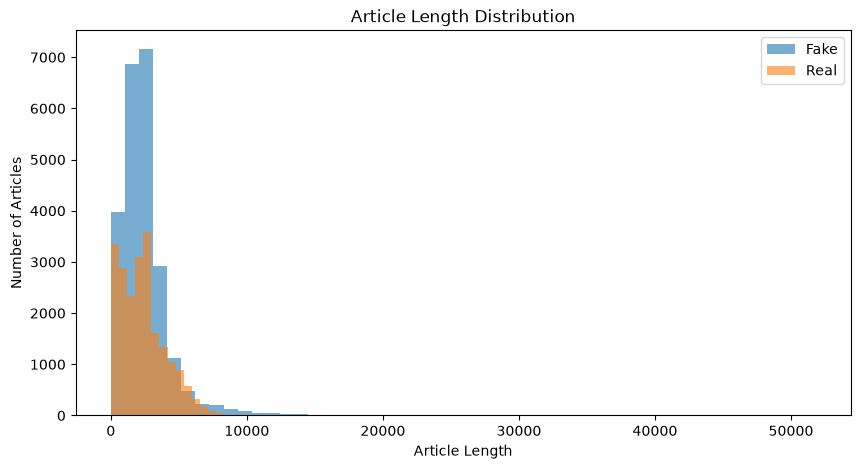

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(fake['text_length'], bins=50, alpha=0.6, label='Fake')
plt.hist(true['text_length'], bins=50, alpha=0.6, label='Real')

plt.xlabel("Article Length")
plt.ylabel("Number of Articles")
plt.title("Article Length Distribution")

plt.legend()
plt.show()

In [11]:
# Make copies so we don't modify the original datasets
fake_clean = fake.copy()
true_clean = true.copy()

# Add labels
fake_clean["label"] = 0
true_clean["label"] = 1

# Keep only the columns we need for the first ML experiment
fake_clean = fake_clean[["title", "text", "label"]]
true_clean = true_clean[["title", "text", "label"]]

# Combine datasets
df = pd.concat([fake_clean, true_clean], ignore_index=True)

print("Combined dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

Combined dataset shape: (44898, 3)

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [12]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())
print("New dataset shape:", df.shape)


Duplicates before: 5793
Duplicates after: 0
New dataset shape: (39105, 3)


In [13]:
print(df["label"].value_counts())

print("\nLabel percentages:")
print(df["label"].value_counts(normalize=True) * 100)

label
1    21197
0    17908
Name: count, dtype: int64

Label percentages:
label
1    54.205345
0    45.794655
Name: proportion, dtype: float64


In [14]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

display(df.head())

,title,text,label
0,Many 'lost' voters say they have found their c...,WASHINGTON/NEW YORK (Reuters) - Ted Wade hasn’...,1
1,"Iranian Revolutionary Guards commander, anothe...",BEIRUT (Reuters) - A commander in Iran s elite...,1
2,Cambodian leader gets China's backing as West ...,PHNOM PENH (Reuters) - Cambodian Prime Ministe...,1
3,Ex-KKK Grand Wizard: Maine Gov. Right To Call...,David Duke is perhaps one of the most notoriou...,0
4,FINGER-WAGGING GRANNY HILLARY CLINTON Blows Up...,Hillary Clinton shows her true colors here wit...,0


In [15]:
print("Duplicate texts:", df["text"].duplicated().sum())

Duplicate texts: 459


In [16]:
print("Duplicate titles:", df["title"].duplicated().sum())

Duplicate titles: 376


In [17]:
print("Empty titles:", (df["title"].str.strip() == "").sum())
print("Empty texts:", (df["text"].str.strip() == "").sum())

Empty titles: 0
Empty texts: 447


In [18]:
print(df.isnull().sum())

title    0
text     0
label    0
dtype: int64


In [19]:
empty_text = df[df["text"].str.strip() == ""]

print("Number of empty text rows:", len(empty_text))

display(empty_text.head(10))

Number of empty text rows: 447


,title,text,label
286,HYSTERICAL! TUCKER CARLSON Slams Geraldo For P...,,0
371,FLASHBACK: CHICAGO RESIDENT Blasts Chicago May...,,0
477,MARK LEVIN Outlines Evidence Of Spying By Obam...,,0
478,FANTASTIC! Watch Boeing Employees Chant “USA U...,,0
491,ALMOST 100 YEARS LATER…Donald Trump Sounds A L...,,0
777,YIKES! HILLARY GOES OFF THE RAILS…Pulls A Howa...,,0
840,MUST SEE VIDEO! Great Final Campaign Rally Mom...,,0
883,WHOA! TRUTH BOMB On Failed Muslim Integration:...,,0
894,DIRTY JOBS’ MIKE ROWE: Great Opportunities Out...,,0
958,DONALD TRUMP’S SEVEN ACTIONS To Protect Americ...,,0


In [20]:
display(empty_text[["title", "text", "label"]].head(10))

,title,text,label
286,HYSTERICAL! TUCKER CARLSON Slams Geraldo For P...,,0
371,FLASHBACK: CHICAGO RESIDENT Blasts Chicago May...,,0
477,MARK LEVIN Outlines Evidence Of Spying By Obam...,,0
478,FANTASTIC! Watch Boeing Employees Chant “USA U...,,0
491,ALMOST 100 YEARS LATER…Donald Trump Sounds A L...,,0
777,YIKES! HILLARY GOES OFF THE RAILS…Pulls A Howa...,,0
840,MUST SEE VIDEO! Great Final Campaign Rally Mom...,,0
883,WHOA! TRUTH BOMB On Failed Muslim Integration:...,,0
894,DIRTY JOBS’ MIKE ROWE: Great Opportunities Out...,,0
958,DONALD TRUMP’S SEVEN ACTIONS To Protect Americ...,,0


In [21]:
duplicate_texts = df[df["text"].duplicated(keep=False)].sort_values("text")

print("Rows involved in duplicate texts:",
      len(duplicate_texts))

display(
    duplicate_texts[["title", "text", "label"]].head(10)
)

Rows involved in duplicate texts: 475


,title,text,label
286,HYSTERICAL! TUCKER CARLSON Slams Geraldo For P...,,0
25582,SHARE THIS EVERYWHERE! DISEASED REFUGEES Get S...,,0
25540,ARROGANT OBAMA Might Want To Scrub This Video ...,,0
25394,BREAKING: Philippines President Announces ‘Sep...,,0
25307,TREY GOWDY TO DEA CHIEF ON MISCONDUCT: “WHAT T...,,0
25223,CLINTON SUPPORTER CARL BERNSTEIN : FBI Found A...,,0
24924,PLAYING POLITICS? HERE’S WHY A JUDGE Will Unse...,,0
24823,TRUMP CHIEF OF STAFF Goes At It With Liberal H...,,0
24709,SHOCKER! A LIBERAL TAKEDOWN Of Hillary Clinton...,,0
24599,TRUMP SPOTTED Wearing New Red Presidential Hat...,,0


In [22]:
text_label_counts = (
    df.groupby("text")["label"]
      .nunique()
)

print(
    "Texts appearing with different labels:",
    (text_label_counts > 1).sum()
)

Texts appearing with different labels: 1


In [24]:
conflicting_texts = df.groupby("text")["label"].nunique()
conflicting_texts = conflicting_texts[conflicting_texts > 1]

print("Number of conflicting texts:", len(conflicting_texts))

for text in conflicting_texts.index:
    print("\nTEXT:")
    print(text[:1000])
    
    print("\nROWS:")
    display(df[df["text"] == text][["title", "text", "label"]])

Number of conflicting texts: 1

TEXT:
 

ROWS:


,title,text,label
286,HYSTERICAL! TUCKER CARLSON Slams Geraldo For P...,,0
371,FLASHBACK: CHICAGO RESIDENT Blasts Chicago May...,,0
477,MARK LEVIN Outlines Evidence Of Spying By Obam...,,0
478,FANTASTIC! Watch Boeing Employees Chant “USA U...,,0
491,ALMOST 100 YEARS LATER…Donald Trump Sounds A L...,,0
...,...,...,...
38892,(VIDEO) MARK STEYN ON ‘AMERICAN RELEVANCE’ IN ...,,0
38913,SMART AS A WHIP! TRUMP BUDGET DIRECTOR Destroy...,,0
38971,(VIDEO) KRAUTHAMMER: FORMER CIA DEPUTY DIRECTO...,,0
39012,BOOM! JULIAN ASSANGE OF WIKILEAKS Drops A Trut...,,0


In [25]:
df["content"] = (
    df["title"].fillna("").str.strip() + " " +
    df["text"].fillna("").str.strip()
).str.strip()

In [26]:
print("Empty content:", (df["content"] == "").sum())

Empty content: 0


In [27]:
print("Duplicates before:", df["content"].duplicated().sum())

df = df.drop_duplicates(subset=["content"]).reset_index(drop=True)

print("Duplicates after:", df["content"].duplicated().sum())
print("Final shape:", df.shape)

Duplicates before: 2
Duplicates after: 0
Final shape: (39103, 4)


In [28]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39103 entries, 0 to 39102
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    39103 non-null  object
 1   text     39103 non-null  object
 2   label    39103 non-null  int64 
 3   content  39103 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.2+ MB
None


In [29]:
print("\nFinal class distribution:")
print(df["label"].value_counts())


Final class distribution:
label
1    21196
0    17907
Name: count, dtype: int64


In [30]:
print("\nFinal dataset shape:")
print(df.shape)


Final dataset shape:
(39103, 4)


In [31]:
display(df[["title", "text", "content", "label"]].head())

,title,text,content,label
0,Many 'lost' voters say they have found their c...,WASHINGTON/NEW YORK (Reuters) - Ted Wade hasn’...,Many 'lost' voters say they have found their c...,1
1,"Iranian Revolutionary Guards commander, anothe...",BEIRUT (Reuters) - A commander in Iran s elite...,"Iranian Revolutionary Guards commander, anothe...",1
2,Cambodian leader gets China's backing as West ...,PHNOM PENH (Reuters) - Cambodian Prime Ministe...,Cambodian leader gets China's backing as West ...,1
3,Ex-KKK Grand Wizard: Maine Gov. Right To Call...,David Duke is perhaps one of the most notoriou...,Ex-KKK Grand Wizard: Maine Gov. Right To Call ...,0
4,FINGER-WAGGING GRANNY HILLARY CLINTON Blows Up...,Hillary Clinton shows her true colors here wit...,FINGER-WAGGING GRANNY HILLARY CLINTON Blows Up...,0


In [32]:
df.to_csv(
    "../data/processed/truthlens_dataset.csv",
    index=False
)

In [33]:
from sklearn.model_selection import train_test_split

X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 31282
Testing samples: 7821

Training class distribution:
label
1    16957
0    14325
Name: count, dtype: int64

Testing class distribution:
label
1    4239
0    3582
Name: count, dtype: int64


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (31282, 50000)
Testing TF-IDF shape: (7821, 50000)


In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [36]:
y_pred = model.predict(X_test_tfidf)

print("Predictions generated!")

Predictions generated!


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake", "Real"]
))

Accuracy : 0.9860631632783532
Precision: 0.9811276794035415
Recall   : 0.9933946685539042
F1 Score : 0.9872230688078771

Classification Report:
              precision    recall  f1-score   support

        Fake       0.99      0.98      0.98      3582
        Real       0.98      0.99      0.99      4239

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



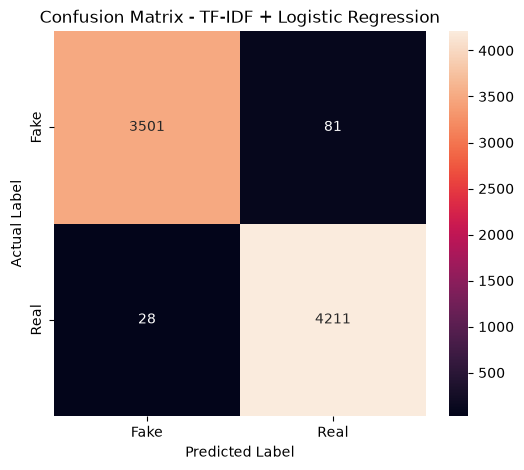

In [41]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - TF-IDF + Logistic Regression")
plt.show()

In [42]:
baseline_results = {
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

baseline_results

{'Model': 'TF-IDF + Logistic Regression',
 'Accuracy': 0.9860631632783532,
 'Precision': 0.9811276794035415,
 'Recall': 0.9933946685539042,
 'F1 Score': 0.9872230688078771}

In [43]:
import numpy as np

feature_names = np.array(tfidf.get_feature_names_out())

coefficients = model.coef_[0]

top_real = feature_names[np.argsort(coefficients)[-20:][::-1]]
top_fake = feature_names[np.argsort(coefficients)[:20]]

print("Top words/features indicating REAL:\n")
print(top_real)

print("\nTop words/features indicating FAKE:\n")
print(top_fake)

Top words/features indicating REAL:

['reuters' 'said' 'washington reuters' 'washington' 'president donald'
 'wednesday' 'tuesday' 'republican' 'thursday' 'reuters president'
 'friday' 'minister' 'monday' 'presidential' 'nov' 'spokesman'
 'democratic' 'told reuters' 'said statement' 'comment']

Top words/features indicating FAKE:

['video' 'just' 'image' 'featured image' 'featured' 'gop' 'hillary' 'read'
 'president trump' 'watch' 'like' 'mr' 'getty' 'america' 'obama'
 'getty images' 'com' 'images' 'president obama' 'american']


In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def run_experiment(X_train_text, X_test_text, y_train, y_test, experiment_name):

    vectorizer = TfidfVectorizer(
        max_features=50000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2
    )

    train_features = vectorizer.fit_transform(X_train_text)
    test_features = vectorizer.transform(X_test_text)

    classifier = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    classifier.fit(train_features, y_train)

    predictions = classifier.predict(test_features)

    results = {
        "Experiment": experiment_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    }

    return results

In [46]:
# Experiment 1: Title only
title_result = run_experiment(
    X_train_text=df.loc[X_train.index, "title"],
    X_test_text=df.loc[X_test.index, "title"],
    y_train=y_train,
    y_test=y_test,
    experiment_name="Title Only"
)

# Experiment 2: Text only
text_result = run_experiment(
    X_train_text=df.loc[X_train.index, "text"],
    X_test_text=df.loc[X_test.index, "text"],
    y_train=y_train,
    y_test=y_test,
    experiment_name="Text Only"
)

# Experiment 3: Title + Text
content_result = run_experiment(
    X_train_text=X_train,
    X_test_text=X_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="Title + Text"
)

results = [title_result, text_result, content_result]

import pandas as pd

comparison_df = pd.DataFrame(results)

comparison_df

,Experiment,Accuracy,Precision,Recall,F1 Score
0,Title Only,0.942335,0.933807,0.961783,0.947589
1,Text Only,0.984912,0.979744,0.992687,0.986173
2,Title + Text,0.986063,0.981128,0.993395,0.987223


In [47]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def run_naive_bayes(X_train_text, X_test_text, y_train, y_test):

    vectorizer = TfidfVectorizer(
        max_features=50000,
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2
    )

    train_features = vectorizer.fit_transform(X_train_text)
    test_features = vectorizer.transform(X_test_text)

    model = MultinomialNB()

    model.fit(train_features, y_train)

    predictions = model.predict(test_features)

    return {
        "Model": "TF-IDF + Naive Bayes",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    }

In [48]:
nb_result = run_naive_bayes(
    X_train_text=X_train,
    X_test_text=X_test,
    y_train=y_train,
    y_test=y_test
)

nb_result

{'Model': 'TF-IDF + Naive Bayes',
 'Accuracy': 0.9569108809615139,
 'Precision': 0.9601415094339623,
 'Recall': 0.9603680113234253,
 'F1 Score': 0.9602547470220545}

In [49]:
import re

def remove_source_cues(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove common source/style indicators
    patterns = [
        r'\breuters\b',
        r'\bgetty images\b',
        r'\bfeatured image\b',
        r'\bfeatured\b',
    ]

    for pattern in patterns:
        text = re.sub(pattern, ' ', text, flags=re.IGNORECASE)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [50]:
df["content_no_source"] = df["content"].apply(remove_source_cues)

print(df[["content", "content_no_source"]].head())

                                             content  \
0  Many 'lost' voters say they have found their c...   
1  Iranian Revolutionary Guards commander, anothe...   
2  Cambodian leader gets China's backing as West ...   
3  Ex-KKK Grand Wizard: Maine Gov. Right To Call ...   
4  FINGER-WAGGING GRANNY HILLARY CLINTON Blows Up...   

                                   content_no_source  
0  Many 'lost' voters say they have found their c...  
1  Iranian Revolutionary Guards commander, anothe...  
2  Cambodian leader gets China's backing as West ...  
3  Ex-KKK Grand Wizard: Maine Gov. Right To Call ...  
4  FINGER-WAGGING GRANNY HILLARY CLINTON Blows Up...  


In [51]:
X_train_clean = df.loc[X_train.index, "content_no_source"]
X_test_clean = df.loc[X_test.index, "content_no_source"]

In [52]:
clean_result = run_experiment(
    X_train_text=X_train_clean,
    X_test_text=X_test_clean,
    y_train=y_train,
    y_test=y_test,
    experiment_name="Title + Text (Source Cues Removed)"
)

print(clean_result)

{'Experiment': 'Title + Text (Source Cues Removed)', 'Accuracy': 0.9817158931082982, 'Precision': 0.9767225325884544, 'Recall': 0.9898560981363529, 'F1 Score': 0.9832454598711189}


In [53]:
robustness_comparison = pd.DataFrame([
    content_result,
    clean_result
])

robustness_comparison

,Experiment,Accuracy,Precision,Recall,F1 Score
0,Title + Text,0.986063,0.981128,0.993395,0.987223
1,Title + Text (Source Cues Removed),0.981716,0.976723,0.989856,0.983245


In [54]:
experiment_results = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Input": "Title + Text",
        "Accuracy": 0.986063,
        "Precision": 0.981128,
        "Recall": 0.993395,
        "F1 Score": 0.987223
    },
    {
        "Model": "TF-IDF + Naive Bayes",
        "Input": "Title + Text",
        "Accuracy": 0.956911,
        "Precision": 0.960142,
        "Recall": 0.960368,
        "F1 Score": 0.960255
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Input": "Title Only",
        "Accuracy": 0.942335,
        "Precision": 0.933807,
        "Recall": 0.961783,
        "F1 Score": 0.947589
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Input": "Text Only",
        "Accuracy": 0.984912,
        "Precision": 0.979744,
        "Recall": 0.992687,
        "F1 Score": 0.986173
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Input": "Source Cues Removed",
        "Accuracy": 0.981716,
        "Precision": 0.976723,
        "Recall": 0.989856,
        "F1 Score": 0.983245
    }
])

experiment_results

,Model,Input,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Logistic Regression,Title + Text,0.986063,0.981128,0.993395,0.987223
1,TF-IDF + Naive Bayes,Title + Text,0.956911,0.960142,0.960368,0.960255
2,TF-IDF + Logistic Regression,Title Only,0.942335,0.933807,0.961783,0.947589
3,TF-IDF + Logistic Regression,Text Only,0.984912,0.979744,0.992687,0.986173
4,TF-IDF + Logistic Regression,Source Cues Removed,0.981716,0.976723,0.989856,0.983245


In [55]:
experiment_results.to_csv(
    "../evaluation/baseline_results.csv",
    index=False
)

print("Baseline results saved!")

Baseline results saved!
